In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
df = pd.read_csv("C:/Users/ahmed/Downloads/ncr_ride_bookings.csv")

In [52]:
df

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,2024-11-11,19:34:01,"""CNR6500631""",Completed,"""CID4337371""",Go Mini,MG Road,Ghitorni,10.2,44.4,...,NaN,NaN,NaN,NaN,NaN,475.0,40.08,3.7,4.1,Uber Wallet
149996,2024-11-24,15:55:09,"""CNR2468611""",Completed,"""CID2325623""",Go Mini,Golf Course Road,Akshardham,5.1,30.8,...,NaN,NaN,NaN,NaN,NaN,1093.0,21.31,4.8,5.0,UPI
149997,2024-09-18,10:55:15,"""CNR6358306""",Completed,"""CID9925486""",Go Sedan,Satguru Ram Singh Marg,Jor Bagh,2.7,23.4,...,NaN,NaN,NaN,NaN,NaN,852.0,15.93,3.9,4.4,Cash
149998,2024-10-05,07:53:34,"""CNR3030099""",Completed,"""CID9415487""",Auto,Ghaziabad,Saidulajab,6.9,39.6,...,NaN,NaN,NaN,NaN,NaN,333.0,45.54,4.1,3.7,UPI


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 
 5   Vehicle Type                       150000 non-null  object 
 6   Pickup Location                    150000 non-null  object 
 7   Drop Location                      150000 non-null  object 
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  1050

In [54]:
df.describe()

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Booking Value,Ride Distance,Driver Ratings,Customer Rating
count,139500.000000,102000.000000,10500.0,27000.0,9000.0,102000.000000,102000.000000,93000.000000,93000.000000
mean,8.456352,29.149636,1.0,1.0,1.0,508.295912,24.637012,4.230992,4.404584
std,3.773564,8.902577,0.0,0.0,0.0,395.805774,14.002138,0.436871,0.437819
min,2.000000,10.000000,1.0,1.0,1.0,50.000000,1.000000,3.000000,3.000000
25%,5.300000,21.600000,1.0,1.0,1.0,234.000000,12.460000,4.100000,4.200000
50%,8.300000,28.800000,1.0,1.0,1.0,414.000000,23.720000,4.300000,4.500000
75%,11.300000,36.800000,1.0,1.0,1.0,689.000000,36.820000,4.600000,4.800000
max,20.000000,45.000000,1.0,1.0,1.0,4277.000000,50.000000,5.000000,5.000000


### Data Cleaning and Preprocessing

In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df.isna().sum()

Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64

In [57]:
df['Ride Start Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])

In [58]:
df['Ride Start Datetime'] = pd.to_datetime(df['Ride Start Datetime'])
daily_vol = df.resample('D', on='Ride Start Datetime').size()


In [59]:
df = df.drop(columns=['Date', 'Time'])

In [60]:
df['Reason for cancelling by Customer'] = df['Reason for cancelling by Customer'].fillna('Not Applicable')
df['Driver Cancellation Reason'] = df['Driver Cancellation Reason'].fillna('Not Applicable')
df['Incomplete Rides Reason'] = df['Incomplete Rides Reason'].fillna('Not Applicable')
df['Payment Method'] = df['Payment Method'].fillna('Unknown')

In [61]:
df['Cancelled Rides by Customer'] = df['Cancelled Rides by Customer'].fillna(0).astype(int)
df['Cancelled Rides by Driver'] = df['Cancelled Rides by Driver'].fillna(0).astype(int)
df['Incomplete Rides'] = df['Incomplete Rides'].fillna(0).astype(int)

In [62]:
for col in ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']:
    if col in df.columns:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 20 columns):
 #   Column                             Non-Null Count   Dtype         
---  ------                             --------------   -----         
 0   Booking ID                         150000 non-null  object        
 1   Booking Status                     150000 non-null  object        
 2   Customer ID                        150000 non-null  object        
 3   Vehicle Type                       150000 non-null  object        
 4   Pickup Location                    150000 non-null  object        
 5   Drop Location                      150000 non-null  object        
 6   Avg VTAT                           150000 non-null  float64       
 7   Avg CTAT                           150000 non-null  float64       
 8   Cancelled Rides by Customer        150000 non-null  int64         
 9   Reason for cancelling by Customer  150000 non-null  object        
 10  Cancelled Rides by D

In [64]:
display(df.head())

,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,Ride Start Datetime
0,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,8.3,28.8,0,Not Applicable,0,Not Applicable,0,Not Applicable,414.0,23.72,4.3,4.5,Unknown,2024-03-23 12:29:38
1,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,0,Not Applicable,0,Not Applicable,1,Vehicle Breakdown,237.0,5.73,4.3,4.5,UPI,2024-11-29 18:01:39
2,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,0,Not Applicable,0,Not Applicable,0,Not Applicable,627.0,13.58,4.9,4.9,Debit Card,2024-08-23 08:56:10
3,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,0,Not Applicable,0,Not Applicable,0,Not Applicable,416.0,34.02,4.6,5.0,UPI,2024-10-21 17:17:25
4,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,0,Not Applicable,0,Not Applicable,0,Not Applicable,737.0,48.21,4.1,4.3,UPI,2024-09-16 22:08:00


In [65]:
df['Driver Ratings'].value_counts()

Driver Ratings
4.3    71081
4.2    13841
4.6     9368
4.4     7018
4.1     6966
4.9     4705
4.7     4678
4.5     4634
3.9     3915
3.8     3848
3.7     3790
5.0     2365
4.8     2328
3.6     2026
4.0     1995
3.2     1538
3.4     1491
3.3     1461
3.1     1459
3.5      748
3.0      745
Name: count, dtype: int64

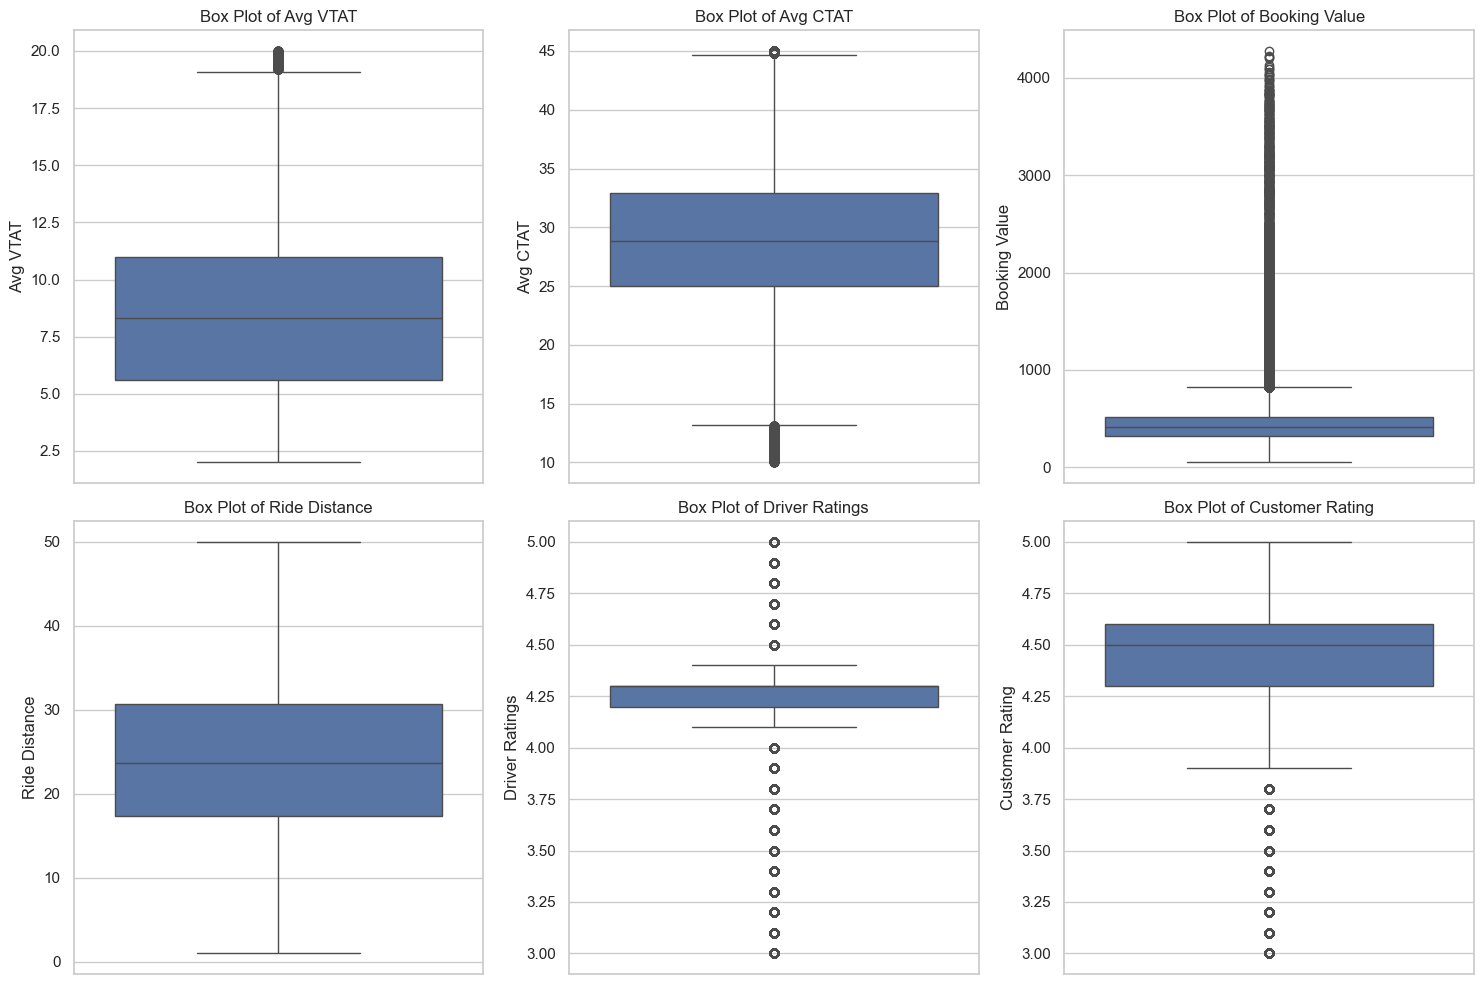

In [66]:
numerical_cols = ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [67]:
df['Driver Ratings'] = df['Driver Ratings'].clip(lower=1.0, upper=5.0)
df['Customer Rating'] = df['Customer Rating'].clip(lower=1.0, upper=5.0)

print("Descriptive statistics for 'Driver Ratings' after capping:")
display(df['Driver Ratings'].describe())

print("\nDescriptive statistics for 'Customer Rating' after capping:")
display(df['Customer Rating'].describe())

Descriptive statistics for 'Driver Ratings' after capping:


count    150000.000000
mean          4.257215
std           0.345619
min           3.000000
25%           4.200000
50%           4.300000
75%           4.300000
max           5.000000
Name: Driver Ratings, dtype: float64


Descriptive statistics for 'Customer Rating' after capping:


count    150000.000000
mean          4.440842
std           0.347835
min           3.000000
25%           4.300000
50%           4.500000
75%           4.600000
max           5.000000
Name: Customer Rating, dtype: float64

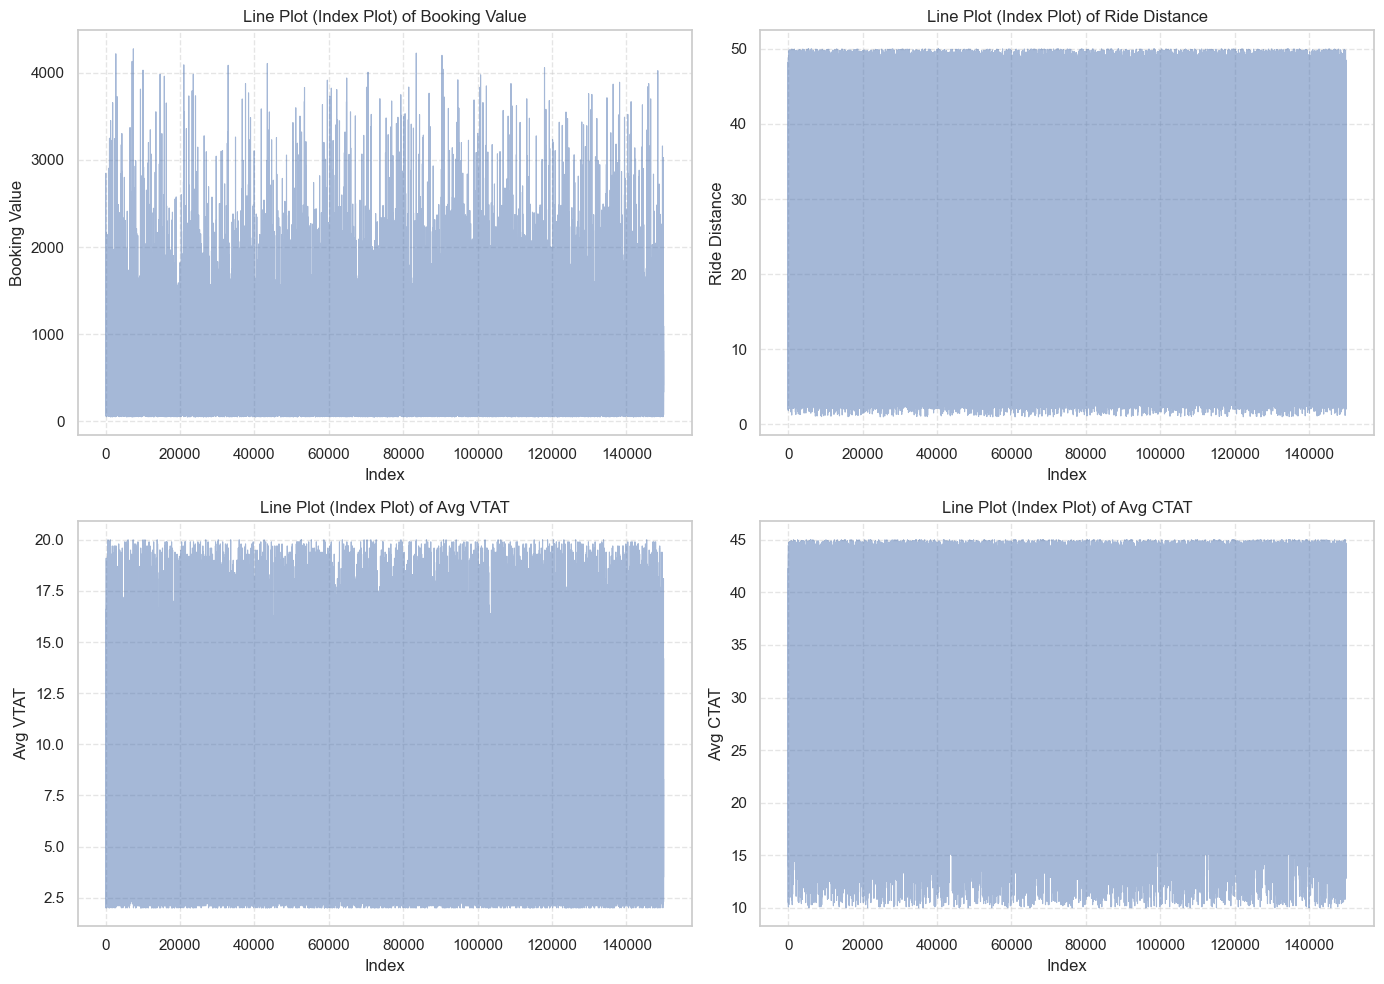

In [68]:
cols_to_plot = ['Booking Value', 'Ride Distance', 'Avg VTAT', 'Avg CTAT']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    axes[i].plot(df.index, df[col], color='b', alpha=0.5, linewidth=0.8)
    axes[i].set_title(f'Line Plot (Index Plot) of {col}', fontsize=12)
    axes[i].set_xlabel('Index')
    axes[i].set_ylabel(col)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Data Analysis

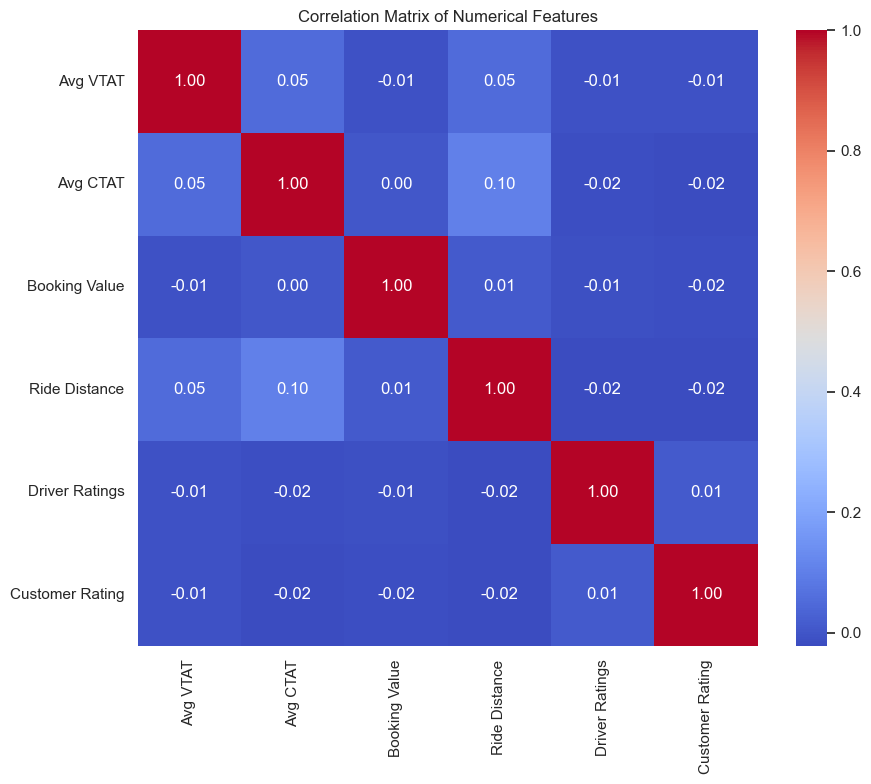

In [69]:
numerical_cols_for_corr = ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']

correlation_matrix = df[numerical_cols_for_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

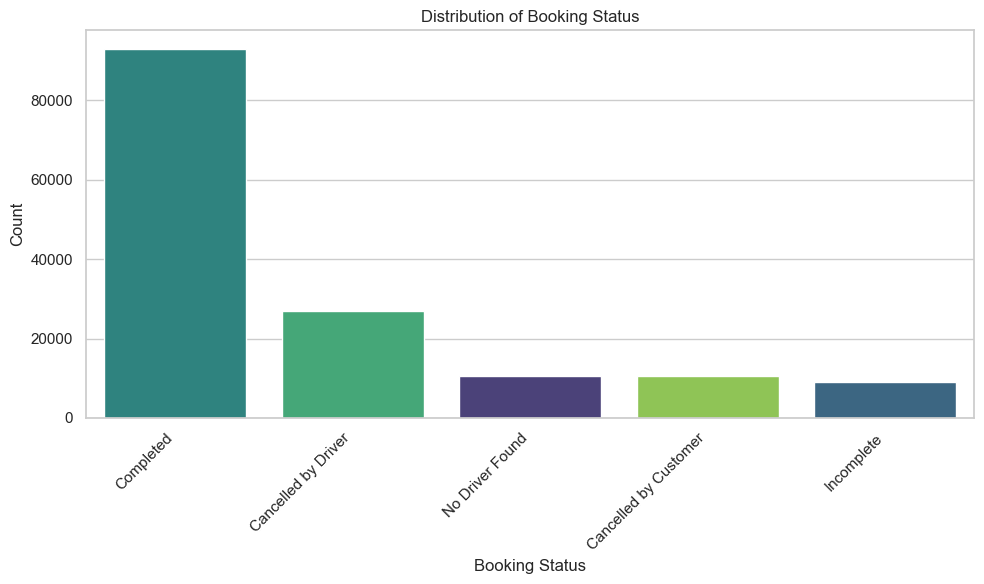

In [70]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Booking Status', order=df['Booking Status'].value_counts().index, hue='Booking Status', palette='viridis', legend=False)
plt.title('Distribution of Booking Status')
plt.xlabel('Booking Status')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

C:\Users\ahmed\AppData\Local\Temp\ipykernel_28608\2648885270.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\ahmed\AppData\Local\Temp\ipykernel_28608\2648885270.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


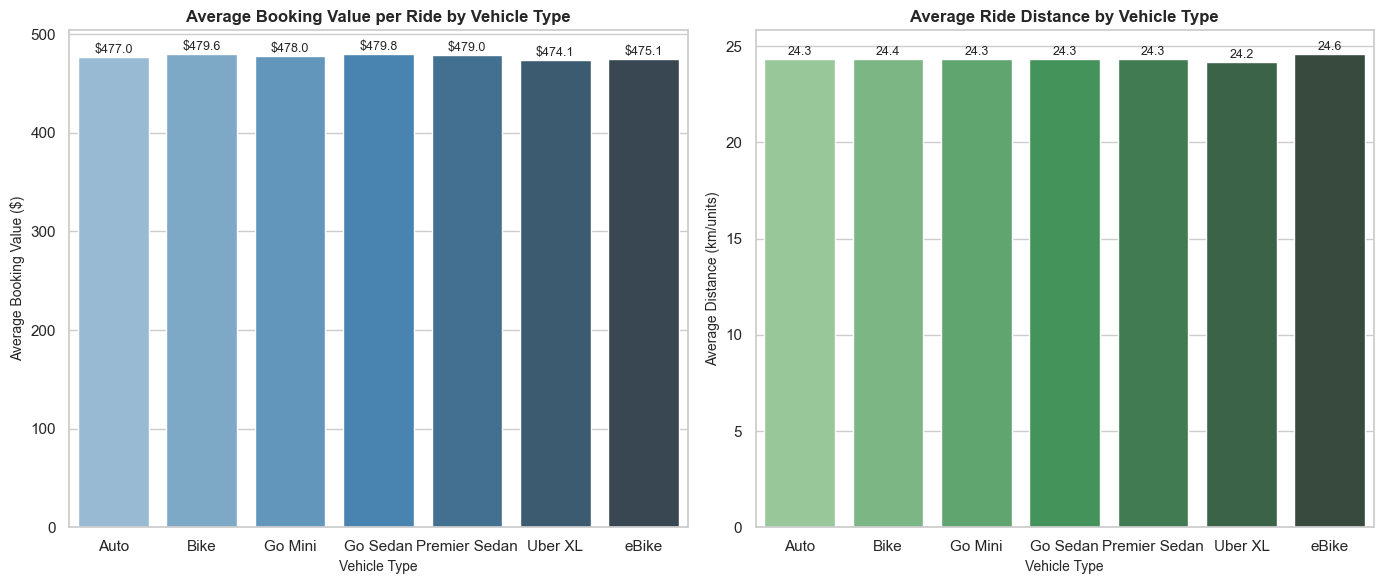

In [71]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

vehicle_value = df.groupby('Vehicle Type')['Booking Value'].mean().reset_index()
sns.barplot(
    data=vehicle_value,
    x='Vehicle Type',
    y='Booking Value',
    palette='Blues_d',
    ax=axes[0]
)
axes[0].set_title('Average Booking Value per Ride by Vehicle Type', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Vehicle Type', fontsize=10)
axes[0].set_ylabel('Average Booking Value ($)', fontsize=10)

for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():.1f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center',
                     xytext=(0, 5),
                     textcoords='offset points', fontsize=9)

vehicle_distance = df.groupby('Vehicle Type')['Ride Distance'].mean().reset_index()
sns.barplot(
    data=vehicle_distance,
    x='Vehicle Type',
    y='Ride Distance',
    palette='Greens_d',
    ax=axes[1]
)
axes[1].set_title('Average Ride Distance by Vehicle Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Vehicle Type', fontsize=10)
axes[1].set_ylabel('Average Distance (km/units)', fontsize=10)

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center',
                     xytext=(0, 5),
                     textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

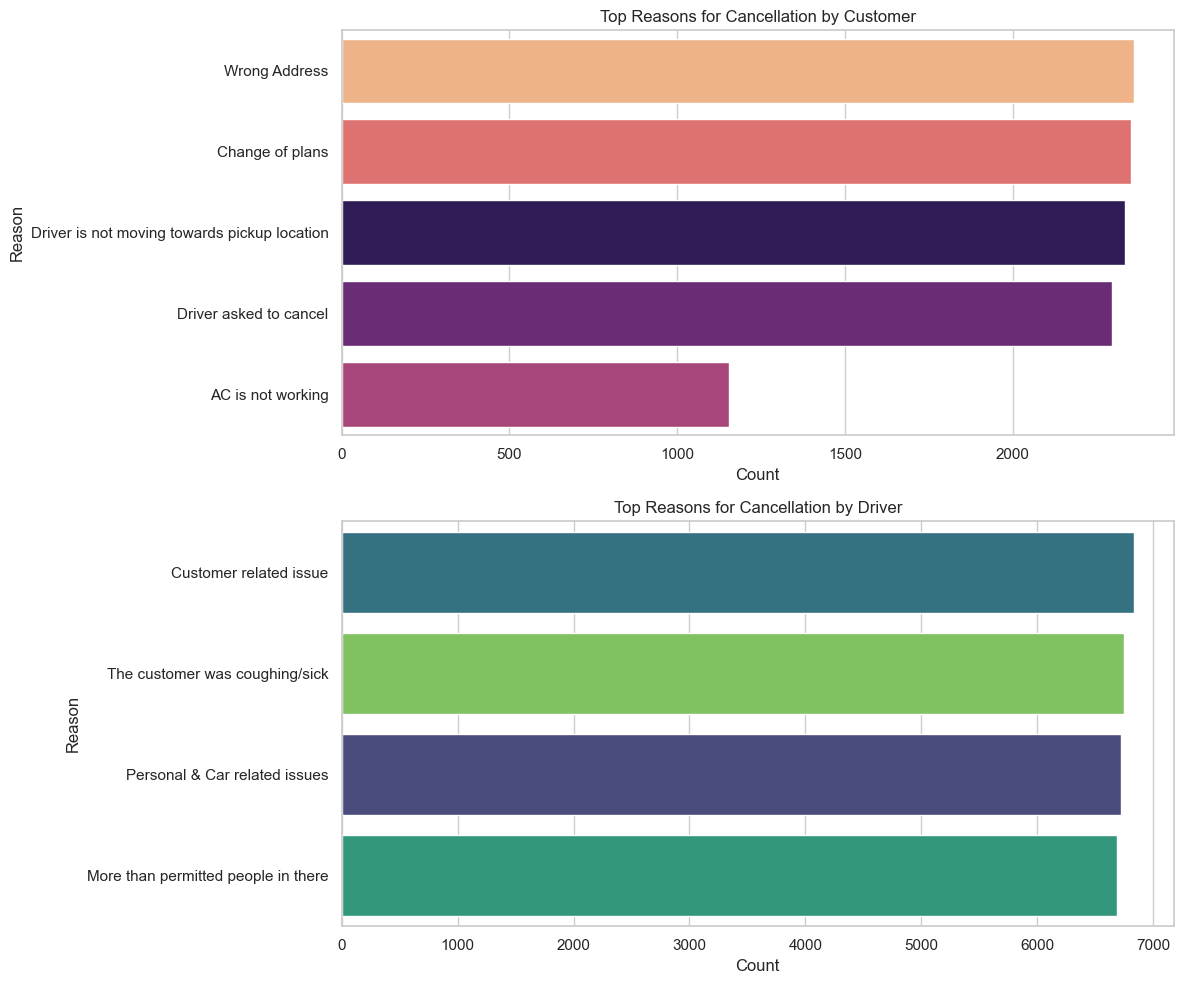

In [72]:
plt.figure(figsize=(12, 10))

customer_cancel_df = df[df['Reason for cancelling by Customer'] != 'Not Applicable']
driver_cancel_df = df[df['Driver Cancellation Reason'] != 'Not Applicable']

plt.subplot(2, 1, 1)
sns.countplot(data=customer_cancel_df, y='Reason for cancelling by Customer',
              order=customer_cancel_df['Reason for cancelling by Customer'].value_counts().index,
              hue='Reason for cancelling by Customer', palette='magma', legend=False)
plt.title('Top Reasons for Cancellation by Customer')
plt.xlabel('Count')
plt.ylabel('Reason')

plt.subplot(2, 1, 2)
sns.countplot(data=driver_cancel_df, y='Driver Cancellation Reason',
              order=driver_cancel_df['Driver Cancellation Reason'].value_counts().index,
              hue='Driver Cancellation Reason', palette='viridis', legend=False)
plt.title('Top Reasons for Cancellation by Driver')
plt.xlabel('Count')
plt.ylabel('Reason')

plt.tight_layout()
plt.show()

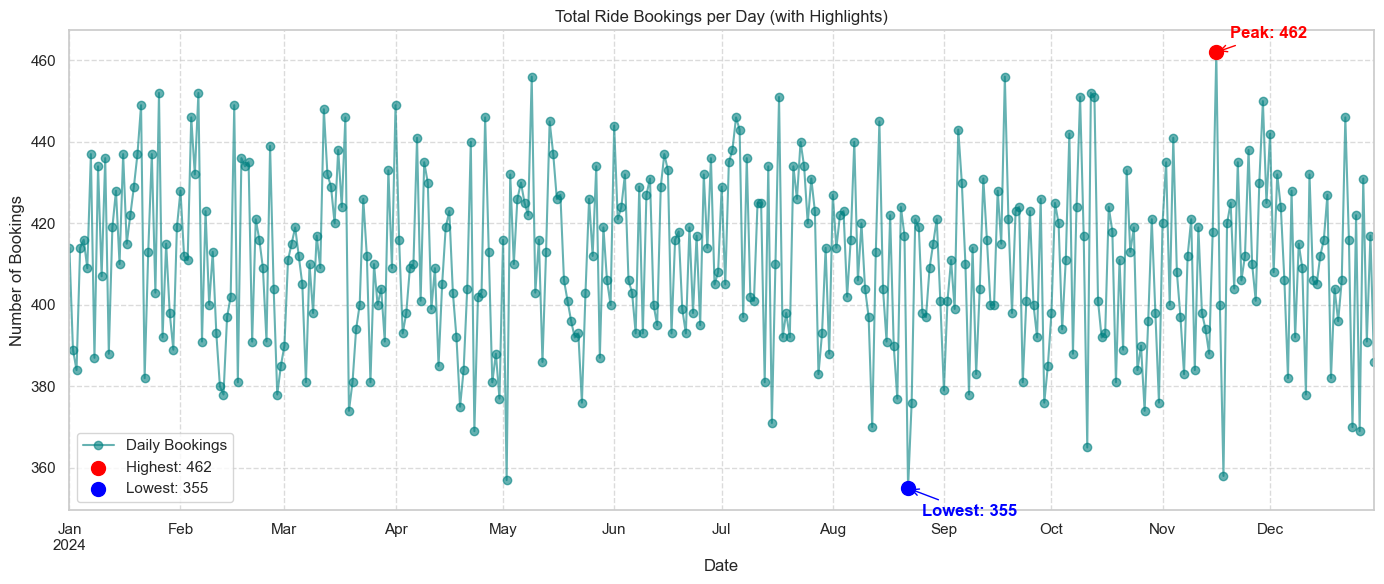

In [73]:
plt.figure(figsize=(14, 6))

daily_bookings = df.resample('D', on='Ride Start Datetime').size()

daily_bookings.plot(kind='line', marker='o', linestyle='-', color='teal', alpha=0.6, label='Daily Bookings')

max_val = daily_bookings.max()
max_date = daily_bookings.idxmax()
min_val = daily_bookings.min()
min_date = daily_bookings.idxmin()

plt.scatter(max_date, max_val, color='red', s=100, zorder=5, label=f'Highest: {max_val}')
plt.annotate(f'Peak: {max_val}', xy=(max_date, max_val), xytext=(10, 10),
             textcoords='offset points', color='red', fontweight='bold', arrowprops=dict(arrowstyle='->', color='red'))

plt.scatter(min_date, min_val, color='blue', s=100, zorder=5, label=f'Lowest: {min_val}')
plt.annotate(f'Lowest: {min_val}', xy=(min_date, min_val), xytext=(10, -20),
             textcoords='offset points', color='blue', fontweight='bold', arrowprops=dict(arrowstyle='->', color='blue'))

plt.title('Total Ride Bookings per Day (with Highlights)')
plt.xlabel('Date')
plt.ylabel('Number of Bookings')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [79]:
%%writefile apps.py
import streamlit as st
st.set_page_config(page_title="Ride Analytics Dashboard", layout="wide")
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

@st.cache_data
def load_data():
    # Tell pandas to treat this specific column as dates right from the start
    df = pd.read_csv(
        'C:/Users/ahmed/Downloads/ncr_ride_bookingccccc.csv', 
        parse_dates=['Ride Start Datetime']
    )
    return df

df = load_data()

st.title("🚖 NCR Ride Bookings: Interactive Visual Analysis")
st.markdown("Explore trends, pricing, and cancellation patterns through interactive filtering.")

# --- Sidebar Filters ---
st.sidebar.header("Dashboard Filters")
vehicle_types = st.sidebar.multiselect("Select Vehicle Type", options=df['Vehicle Type'].unique(), default=df['Vehicle Type'].unique())
booking_status = st.sidebar.multiselect("Select Booking Status", options=df['Booking Status'].unique(), default=df['Booking Status'].unique())

# Apply Filters
mask = (df['Vehicle Type'].isin(vehicle_types)) & (df['Booking Status'].isin(booking_status))
filtered_df = df[mask]

# --- Key Metrics ---
m1, m2, m3 = st.columns(3)
m1.metric("Total Selected Rides", len(filtered_df))
m2.metric("Avg. Booking Value", f"${filtered_df['Booking Value'].mean():.2f}")
m3.metric("Avg. Distance", f"{filtered_df['Ride Distance'].mean():.2f} km")

# --- Visualizations ---
st.subheader("📈 Ride Volume Over Time")
daily_vol = filtered_df.resample('D', on='Ride Start Datetime').size()
fig1, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(daily_vol.index, daily_vol.values, color='#2c7fb8', linewidth=2)
ax1.set_title("Daily Booking Counts")
st.pyplot(fig1)

col1, col2 = st.columns(2)

with col1:
    st.subheader("📊 Booking Status Distribution")
    fig2, ax2 = plt.subplots()
    status_data = filtered_df['Booking Status'].value_counts()
    sns.barplot(x=status_data.values, y=status_data.index, hue=status_data.index, palette='viridis', ax=ax2, legend=False)
    st.pyplot(fig2)

with col2:
    st.subheader("💰 Value vs Distance Correlation")
    fig3, ax3 = plt.subplots()
    # Sample for performance if dataset is huge
    sample_df = filtered_df.sample(min(len(filtered_df), 1000))
    sns.scatterplot(data=sample_df, x='Ride Distance', y='Booking Value', hue='Vehicle Type', alpha=0.6, ax=ax3)
    st.pyplot(fig3)

st.subheader("🚫 Cancellation Deep Dive")
c1, c2 = st.columns(2)
with c1:
    st.write("**Customer Cancellation Reasons**")
    cust_reasons = filtered_df[filtered_df['Reason for cancelling by Customer'] != 'Not Applicable']
    if not cust_reasons.empty:
        fig4, ax4 = plt.subplots()
        sns.countplot(data=cust_reasons, y='Reason for cancelling by Customer', order=cust_reasons['Reason for cancelling by Customer'].value_counts().index[:5], palette='magma', ax=ax4)
        st.pyplot(fig4)
    else:
        st.info("No customer cancellations in filtered data.")

with c2:
    st.write("**Driver Cancellation Reasons**")
    driv_reasons = filtered_df[filtered_df['Driver Cancellation Reason'] != 'Not Applicable']
    if not driv_reasons.empty:
        fig5, ax5 = plt.subplots()
        sns.countplot(data=driv_reasons, y='Driver Cancellation Reason', order=driv_reasons['Driver Cancellation Reason'].value_counts().index[:5], palette='flare', ax=ax5)
        st.pyplot(fig5)
    else:
        st.info("No driver cancellations in filtered data.")

st.markdown("--- ")
st.write("**Raw Data Preview (Filtered)**")
st.dataframe(filtered_df.head(50))

Overwriting apps.py
